# Notebook 04: Giai đoạn 3 — ESPCN (kênh Y BT.601, batch 1 lần) + Richardson–Lucy + làm nét chống halo
- ESPCN nhận **Y của YCrCb** (không phải $L^*$ của LAB); mọi tile 224×224 được gom thành 1 batch.
- Cổng biên dùng gradient chuẩn hoá theo độ phân giải ($\times h/480$) và theo nhiễu ($\ge 2.5\hat\sigma$).
- **Chống halo**: kết quả bị kẹp trong $[\min_{N}(Y)-m,\ \max_{N}(Y)+m]$ của ảnh gốc ⇒ không còn viền cứng quanh mảng phẳng.
- Upscale **giữ tỷ lệ khung hình** (4:3 → 960×720 / 1440×1080; 16:9 → 1280×720 / 1920×1080).

800x600 -> HD 960x720 -> FullHD 1440x1080


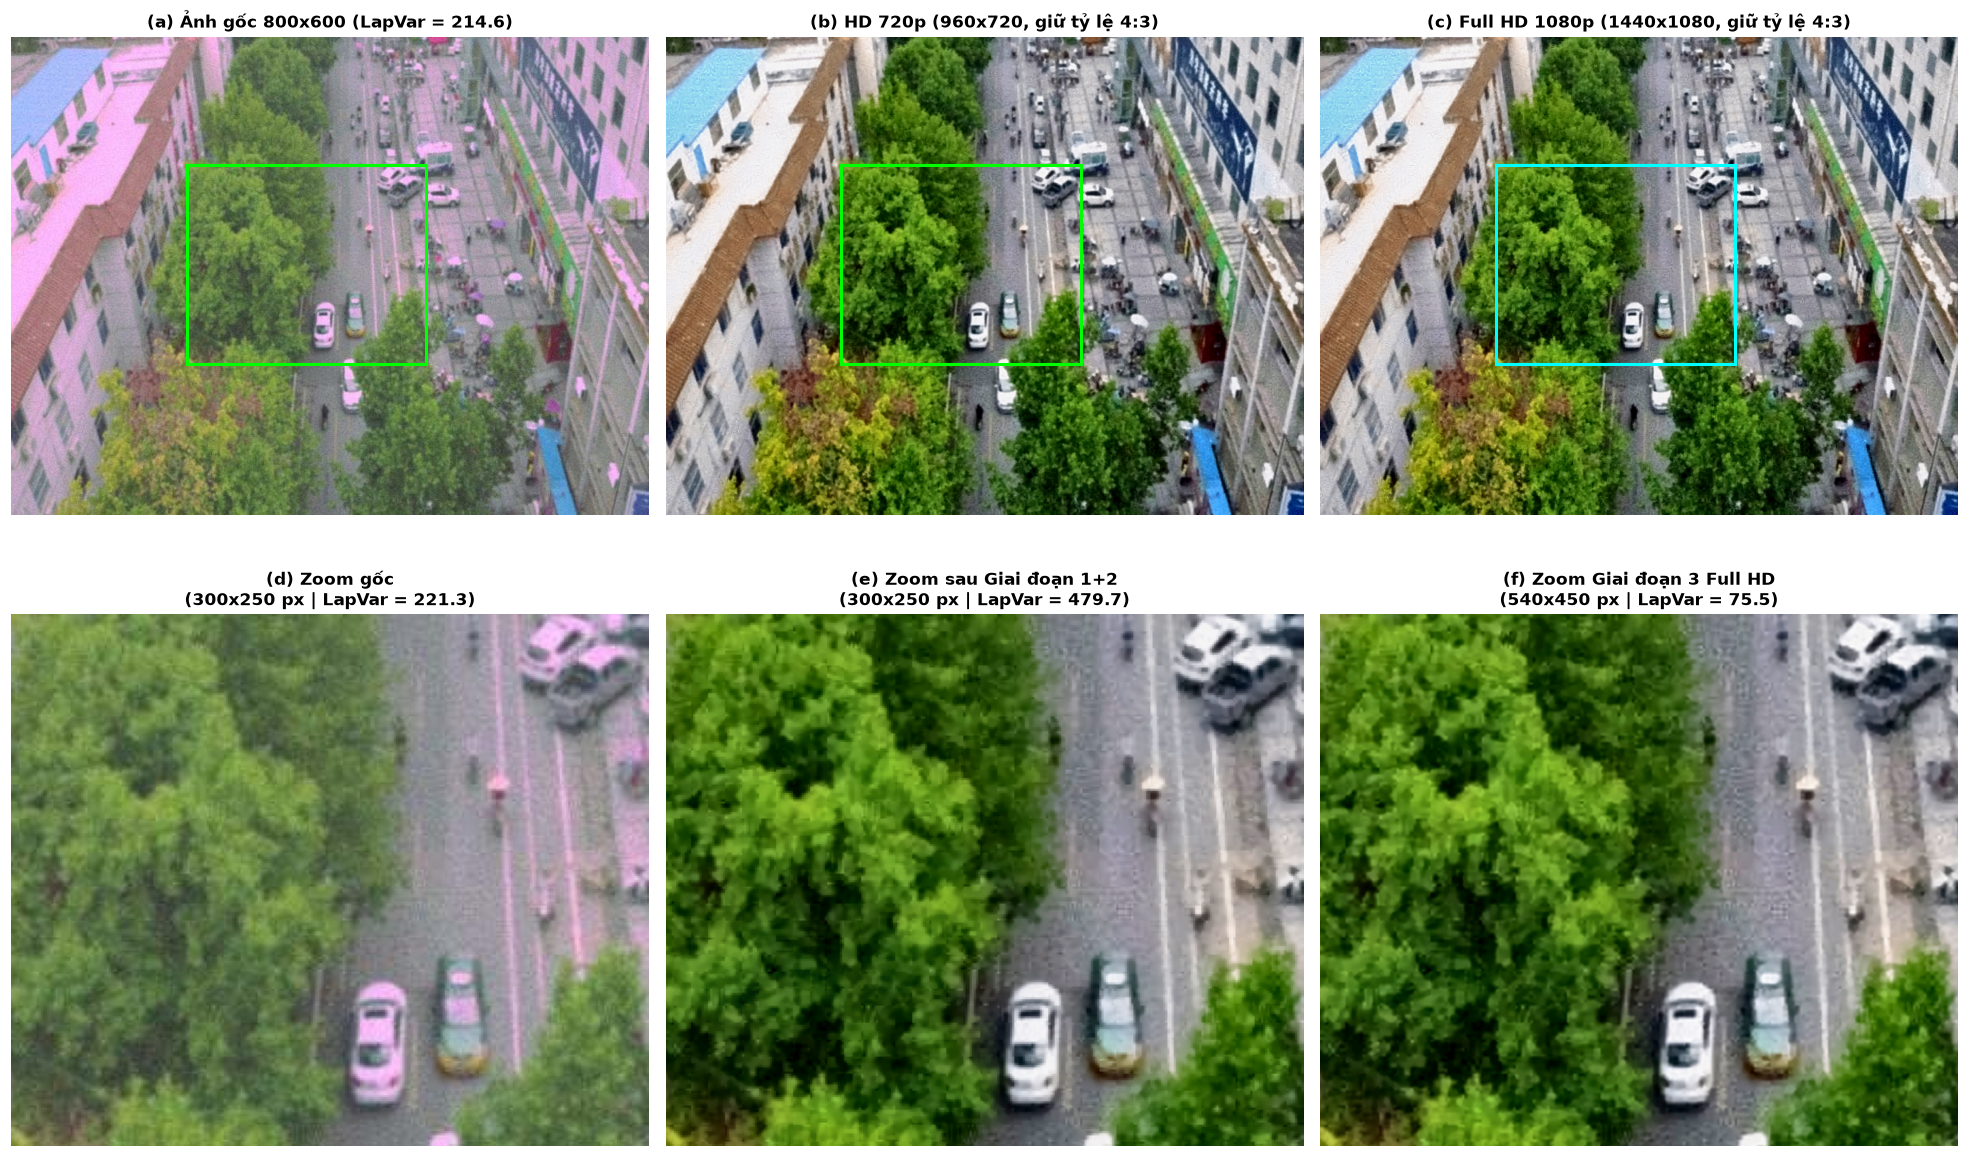

In [1]:
import os, sys, cv2, pandas as pd
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))  # notebook đặt trong notebooks/
sys.path.insert(0, ROOT)
from src.uav_pipeline import run_full_pipeline
img = cv2.imread(f"{ROOT}/data/samples/sample_sim_pink_road_1.jpg")
res = run_full_pipeline(img, return_intermediates=True, hd_heights=(720, 1080))
print(res["output_720p"].shape, res["output_1080p"].shape)